# 04 – Water Level Data Migration
## A teljes vízállás-adatállomány előállítása (2016–2026)

## A notebook célja

A 03-as projekt-újraértékelésben meghozott döntés alapján a fő elemzés a vízállás-adatokra koncentrál. Ebben a migrációban ezért **nem követelmény a vízhőmérsékleti adat megléte**.

A nyers CSV-fájlokból minden olyan rekordot megtartunk, amelynél:
- az `Időpont` értelmezhető dátum-idő érték;
- a felszíni vízállás numerikus értékké alakítható.

A vízhőmérséklet oszlopát nem használjuk szűrési feltételként. Nem töröljük a nyers forrásfájlokból, de a fő vízállás-adatállományba nem emeljük át.

**Fontos adatkezelési döntések**
- Az eredeti CSV-fájlok változatlanok maradnak.
- Minden érvényes vízállásrekordot megtartunk.
- Nem vonjuk össze és nem átlagoljuk az azonos napra eső méréseket.
- Nem töröljük automatikusan az esetleges ismétlődő rekordokat.
- A forrásfájl nevét és a fájlon belüli sorszámot megőrizzük a visszakereshetőséghez.

Az így létrehozott adatállomány lesz a további vízállás-EDA alapja.

## Az időszak teljessége

A vizsgált adatsor időbeli határai:
- **Kezdet:** 2016. szeptember 30.
- **Vég:** 2026. szeptember 30.

Ezért a 2016-os és a 2026-os naptári év nem teljes:
- 2016-ban csak szeptember 30-tól december 31-ig áll rendelkezésre adat;
- 2026-ban január 1-től szeptember 30-ig áll rendelkezésre adat.

A 2017–2025 közötti naptári évek a megadott időhatárok alapján teljes évek. A két szélső év rekorddarabszáma ezért nem hasonlítható közvetlenül a teljes naptári évek rekorddarabszámához. A 2016-os és 2026-os adatokat megtartjuk, de az éves összesítésekben és ábrákon külön jelöljük a részleges éveket.


## 1. Projektkönyvtárak és oszlopnevek

A projekt gyökérkönyvtára a korábban megadott hely. Ha a projektet áthelyezed, a `PROJECT_DIR` értékét kell módosítani.


In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    r"C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT"
)
RAW_DIR = PROJECT_DIR / "Raw_data_2016-2026"
INTERIM_DIR = PROJECT_DIR / "data" / "interim"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports"

for folder in [INTERIM_DIR, PROCESSED_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATETIME_COL = "Időpont"
WATER_LEVEL_TEXT = "Felszíni vízállás"

print("Projekt:", PROJECT_DIR)
print("Nyers adatok:", RAW_DIR)

if not RAW_DIR.exists():
    raise FileNotFoundError(f"Nem található a nyers adatkönyvtár: {RAW_DIR}")


Projekt: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT
Nyers adatok: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\Raw_data_2016-2026


## 2. A forrásfájlok azonosítása

A `YYYY-YY.csv` mintának megfelelő fájlokat dolgozzuk fel. A notebook nem módosítja és nem helyezi át a forrásfájlokat.


In [2]:
filename_pattern = re.compile(r"^\d{4}-\d{2}\.csv$", flags=re.IGNORECASE)
csv_files = sorted(
    p for p in RAW_DIR.glob("*.csv")
    if filename_pattern.match(p.name)
)

if not csv_files:
    raise FileNotFoundError(
        "Nem található a YYYY-YY.csv névmintának megfelelő fájl."
    )

print(f"Feldolgozandó fájlok száma: {len(csv_files)}")
for file_path in csv_files:
    print(f"- {file_path.name} ({file_path.stat().st_size / 1024:,.1f} kB)")


Feldolgozandó fájlok száma: 10
- 2016-17.csv (228.9 kB)
- 2017-18.csv (220.7 kB)
- 2018-19.csv (223.1 kB)
- 2019-20.csv (236.9 kB)
- 2020-21.csv (228.6 kB)
- 2021-22.csv (595.1 kB)
- 2022-23.csv (761.7 kB)
- 2023-24.csv (750.9 kB)
- 2024-25.csv (738.4 kB)
- 2025-26.csv (720.0 kB)


## 3. Beolvasási és átalakítási függvények

A beolvasás több gyakori kódolást és elválasztójelet próbál. A vízállásoszlopot a fejlécben szereplő szövegrész alapján azonosítjuk, így a sortörés vagy a szóközök kisebb eltérései nem okoznak hibát.

Az időpontot dátum-idő típussá, a vízállást numerikus típussá alakítjuk. A nem értelmezhető értékek hiányzóként jelennek meg, és a minőségellenőrzésben külön számoljuk őket.


In [3]:
ENCODINGS = ["utf-8-sig", "cp1250", "latin2", "utf-8"]
SEPARATORS = [";", ",", "\t"]

def read_source_csv(file_path):
    errors = []
    for encoding in ENCODINGS:
        for separator in SEPARATORS:
            try:
                frame = pd.read_csv(
                    file_path,
                    sep=separator,
                    encoding=encoding,
                    engine="python"
                )
                if frame.shape[1] >= 2:
                    return frame, encoding, separator
                errors.append(
                    f"{encoding}, {repr(separator)}: csak {frame.shape[1]} oszlop"
                )
            except Exception as exc:
                errors.append(
                    f"{encoding}, {repr(separator)}: "
                    f"{type(exc).__name__}: {exc}"
                )
    raise ValueError(
        f"Nem sikerült beolvasni: {file_path.name}\n" + "\n".join(errors)
    )


def normalize_header(value):
    """Fejléc összehasonlításához eltávolítja a sortöréseket és többszörös szóközöket."""
    return " ".join(str(value).replace("\n", " ").split()).casefold()


def find_column(columns, required_text):
    matches = [
        col for col in columns
        if required_text.casefold() in normalize_header(col)
    ]
    if len(matches) != 1:
        raise ValueError(
            f"A '{required_text}' alapján {len(matches)} oszlop található: "
            f"{list(matches)}. Ellenőrizd a forrásfájl fejlécét."
        )
    return matches[0]


def parse_datetime(series):
    text = series.astype("string").str.strip()
    try:
        return pd.to_datetime(
            text, errors="coerce", dayfirst=True, format="mixed"
        )
    except TypeError:
        return pd.to_datetime(text, errors="coerce", dayfirst=True)


def parse_numeric(series):
    text = series.astype("string").str.strip()
    text = text.replace({
        "": pd.NA,
        "-": pd.NA,
        "—": pd.NA,
        "–": pd.NA,
        "n.a.": pd.NA,
        "N/A": pd.NA,
        "None": pd.NA
    })
    text = text.str.replace(",", ".", regex=False)
    return pd.to_numeric(text, errors="coerce")


## 4. Vízállásadatok migrációja

Fájlonként csak az időpont- és vízállásoszlopot olvassuk át a közös adatstruktúrába. A vízhőmérséklet oszlopát szándékosan nem használjuk.

A `forras_fajl` és `forras_rekord_sorszama` mezők megőrzik az eredeti rekord visszakereshetőségét.


In [4]:
migrated_frames = []
source_log_rows = []

for file_path in csv_files:
    raw, encoding, separator = read_source_csv(file_path)

    if DATETIME_COL not in raw.columns:
        raise ValueError(
            f"A(z) {file_path.name} fájlban nem található az '{DATETIME_COL}' oszlop. "
            f"Tényleges oszlopok: {list(raw.columns)}"
        )

    water_level_col = find_column(raw.columns, WATER_LEVEL_TEXT)

    migrated = pd.DataFrame({
        "idopont": parse_datetime(raw[DATETIME_COL]),
        "vizallas_cm": parse_numeric(raw[water_level_col]),
        "forras_fajl": file_path.name,
        "forras_rekord_sorszama": np.arange(1, len(raw) + 1)
    })

    migrated_frames.append(migrated)

    source_log_rows.append({
        "fájlnév": file_path.name,
        "forrásrekordok": len(raw),
        "fájlméret_kB": round(file_path.stat().st_size / 1024, 1),
        "kódolás": encoding,
        "elválasztó": repr(separator),
        "dátumoszlop": DATETIME_COL,
        "vízállásoszlop": str(water_level_col)
    })

all_water_level_records = pd.concat(migrated_frames, ignore_index=True)
source_log = pd.DataFrame(source_log_rows)

display(source_log)
print("Összes beolvasott rekord:", f"{len(all_water_level_records):,}")
display(all_water_level_records.head())


,fájlnév,forrásrekordok,fájlméret_kB,kódolás,elválasztó,dátumoszlop,vízállásoszlop
0,2016-17.csv,10681,228.9,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
1,2017-18.csv,10341,220.7,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
2,2018-19.csv,10380,223.1,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
3,2019-20.csv,11068,236.9,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
4,2020-21.csv,10664,228.6,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
5,2021-22.csv,28186,595.1,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
6,2022-23.csv,35109,761.7,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
7,2023-24.csv,35209,750.9,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
8,2024-25.csv,35122,738.4,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)
9,2025-26.csv,35045,720.0,utf-8-sig,';',Időpont,Siófok [2888]\n Felszíni vízállás (cm)


Összes beolvasott rekord: 221,805


,idopont,vizallas_cm,forras_fajl,forras_rekord_sorszama
0,2016-09-30 00:30:00,113.0,2016-17.csv,1
1,2016-09-30 04:15:00,113.0,2016-17.csv,2
2,2016-09-30 06:45:00,115.0,2016-17.csv,3
3,2016-09-30 07:00:00,114.0,2016-17.csv,4
4,2016-09-30 07:15:00,113.0,2016-17.csv,5


## 5. Adatminőségi ellenőrzés a vízállás-adatokon

A rekord akkor érvényes, ha az időpont és a vízállás egyaránt értelmezhető. A vízhőmérséklet megléte vagy hiánya itt nem befolyásolja a megtartást.


In [5]:
quality_by_file = (
    all_water_level_records
    .groupby("forras_fajl", sort=True)
    .agg(
        beolvasott_rekord=("forras_rekord_sorszama", "size"),
        hianyzo_idopont=("idopont", lambda s: int(s.isna().sum())),
        hianyzo_vizallas=("vizallas_cm", lambda s: int(s.isna().sum()))
    )
    .reset_index()
)

display(quality_by_file)

print("Hiányzó vagy nem értelmezhető időpont:",
      f"{all_water_level_records['idopont'].isna().sum():,}")
print("Hiányzó vagy nem numerikus vízállás:",
      f"{all_water_level_records['vizallas_cm'].isna().sum():,}")


,forras_fajl,beolvasott_rekord,hianyzo_idopont,hianyzo_vizallas
0,2016-17.csv,10681,0,0.0
1,2017-18.csv,10341,0,0.0
2,2018-19.csv,10380,0,0.0
3,2019-20.csv,11068,0,0.0
4,2020-21.csv,10664,0,0.0
5,2021-22.csv,28186,0,0.0
6,2022-23.csv,35109,0,0.0
7,2023-24.csv,35209,0,0.0
8,2024-25.csv,35122,0,2.0
9,2025-26.csv,35045,0,1.0


Hiányzó vagy nem értelmezhető időpont: 0
Hiányzó vagy nem numerikus vízállás: 3


## 6. Érvényes vízállásrekordok kiválasztása

A megtartási feltétel kizárólag két mezőre vonatkozik:
- érvényes időpont;
- érvényes numerikus vízállás.

A vízhőmérsékletet nem vizsgáljuk, és nem használjuk szűrésre.


In [6]:
valid_mask = (
    all_water_level_records["idopont"].notna()
    & all_water_level_records["vizallas_cm"].notna()
)

water_level_data = all_water_level_records.loc[valid_mask].copy()

print("Beolvasott rekordok:", f"{len(all_water_level_records):,}")
print("Megtartott vízállásrekordok:", f"{len(water_level_data):,}")
print("Kizárt rekordok:", f"{len(all_water_level_records) - len(water_level_data):,}")
print(
    "Megtartott arány:",
    f"{len(water_level_data) / len(all_water_level_records) * 100:.2f}%"
    if len(all_water_level_records) else "n/a"
)

assert water_level_data["idopont"].notna().all()
assert water_level_data["vizallas_cm"].notna().all()


Beolvasott rekordok: 221,805
Megtartott vízállásrekordok: 221,802
Kizárt rekordok: 3
Megtartott arány: 100.00%


## 7. Fájlonkénti migrációs összesítő

A fájlonkénti táblázat megmutatja, hogy az egyes CSV-fájlokból hány vízállásrekord került át a végleges adatállományba.


In [7]:
retained_by_file = (
    water_level_data.groupby("forras_fajl")
    .size()
    .rename("megtartott_vizallasrekord")
    .reset_index()
)

migration_summary_by_file = quality_by_file.merge(
    retained_by_file, on="forras_fajl", how="left"
)
migration_summary_by_file["megtartott_vizallasrekord"] = (
    migration_summary_by_file["megtartott_vizallasrekord"]
    .fillna(0).astype(int)
)
migration_summary_by_file["kizart_rekord"] = (
    migration_summary_by_file["beolvasott_rekord"]
    - migration_summary_by_file["megtartott_vizallasrekord"]
)

display(migration_summary_by_file)


,forras_fajl,beolvasott_rekord,hianyzo_idopont,hianyzo_vizallas,megtartott_vizallasrekord,kizart_rekord
0,2016-17.csv,10681,0,0.0,10681,0
1,2017-18.csv,10341,0,0.0,10341,0
2,2018-19.csv,10380,0,0.0,10380,0
3,2019-20.csv,11068,0,0.0,11068,0
4,2020-21.csv,10664,0,0.0,10664,0
5,2021-22.csv,28186,0,0.0,28186,0
6,2022-23.csv,35109,0,0.0,35109,0
7,2023-24.csv,35209,0,0.0,35209,0
8,2024-25.csv,35122,0,2.0,35120,2
9,2025-26.csv,35045,0,1.0,35044,1


## 8. Időbeli tartomány és rekordok eloszlása

Ellenőrizzük az adatállomány legkorábbi és legkésőbbi időpontját, valamint az éves rekordmennyiséget. Ez még nem a részletes EDA; itt a migráció eredményének alapvető ellenőrzését végezzük el.

Az éves darabszám a rekordok időpontjából képzett naptári év szerinti összesítés. Nem jelent napi aggregálást: minden eredeti, érvényes rekord külön sor marad.


Első időpont: 2016-09-30 00:30:00
Utolsó időpont: 2026-09-30 03:00:00


,ev,rekordok_szama,idoszak_teljessege,megjegyzes
0,2016,2639,Részleges év,Adatkezdés: 2016-09-30
1,2017,10827,Teljes naptári év,
2,2018,9943,Teljes naptári év,
3,2019,10603,Teljes naptári év,
4,2020,10675,Teljes naptári év,
5,2021,11106,Teljes naptári év,
6,2022,34453,Teljes naptári év,
7,2023,35105,Teljes naptári év,
8,2024,35211,Teljes naptári év,
9,2025,35123,Teljes naptári év,


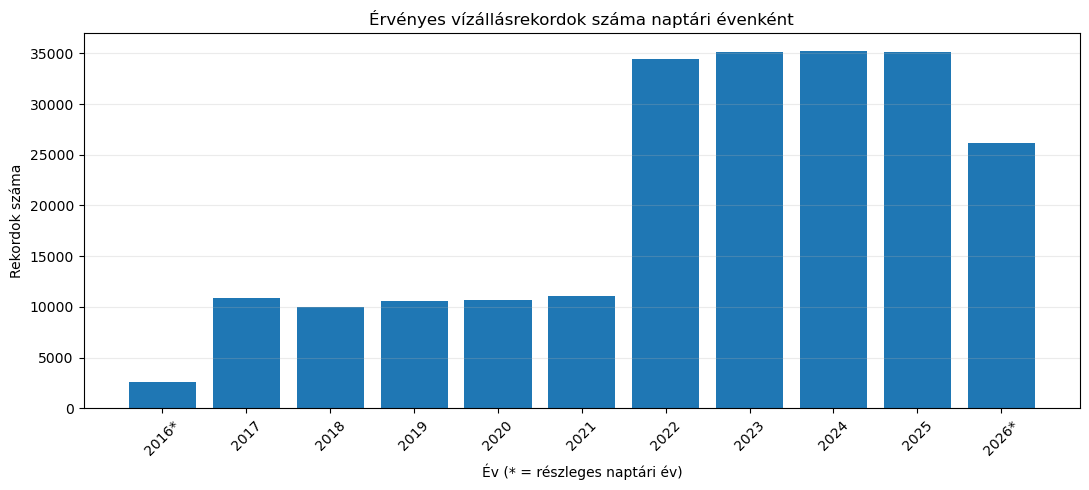

* 2016: 2016. szeptember 30-tól; 2026: 2026. szeptember 30-ig.


In [8]:
if not water_level_data.empty:
    print("Első időpont:", water_level_data["idopont"].min())
    print("Utolsó időpont:", water_level_data["idopont"].max())

    water_level_data["ev"] = water_level_data["idopont"].dt.year

    annual_counts = (
        water_level_data.groupby("ev")
        .size()
        .rename("rekordok_szama")
        .reset_index()
    )

    # A vizsgálati időszak két szélső naptári éve nem teljes.
    annual_counts["idoszak_teljessege"] = np.where(
        annual_counts["ev"].isin([2016, 2026]),
        "Részleges év",
        "Teljes naptári év"
    )
    annual_counts["megjegyzes"] = annual_counts["ev"].map({
        2016: "Adatkezdés: 2016-09-30",
        2026: "Adatvég: 2026-09-30"
    }).fillna("")

    display(annual_counts)

    # A részleges éveket csillaggal jelöljük az ábrán.
    year_labels = [
        f"{year}*" if year in [2016, 2026] else str(year)
        for year in annual_counts["ev"]
    ]

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(year_labels, annual_counts["rekordok_szama"])
    ax.set_title("Érvényes vízállásrekordok száma naptári évenként")
    ax.set_xlabel("Év (* = részleges naptári év)")
    ax.set_ylabel("Rekordok száma")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print("* 2016: 2016. szeptember 30-tól; 2026: 2026. szeptember 30-ig.")
else:
    raise ValueError("A migráció után nem maradt egyetlen érvényes vízállásrekord sem.")


## 9. Ismétlődő rekordok ellenőrzése – törlés nélkül

Megszámoljuk az azonos időponttal és azonos vízállással szereplő rekordokat. Ezeket ebben a migrációban nem töröljük, mert előbb meg kell érteni, hogy valódi ismétlések, párhuzamos forrásbejegyzések vagy mérési sajátosságok állnak-e mögöttük.

A forrásfájl és a forrássor sorszáma minden esetben megmarad.


In [9]:
duplicate_mask = water_level_data.duplicated(
    subset=["idopont", "vizallas_cm"],
    keep=False
)

print("Azonos időponttal és vízállással szereplő rekordok száma:",
      f"{int(duplicate_mask.sum()):,}")

if duplicate_mask.any():
    display(
        water_level_data.loc[duplicate_mask]
        .sort_values(["idopont", "vizallas_cm"])
        .head(20)
    )


Azonos időponttal és vízállással szereplő rekordok száma: 1,052


,idopont,vizallas_cm,forras_fajl,forras_rekord_sorszama,ev
10657,2017-09-30 00:30:00,93.0,2016-17.csv,10658,2017
10681,2017-09-30 00:30:00,93.0,2017-18.csv,1,2017
10658,2017-09-30 02:00:00,91.0,2016-17.csv,10659,2017
10682,2017-09-30 02:00:00,91.0,2017-18.csv,2,2017
10659,2017-09-30 03:45:00,91.0,2016-17.csv,10660,2017
10683,2017-09-30 03:45:00,91.0,2017-18.csv,3,2017
10660,2017-09-30 05:15:00,91.0,2016-17.csv,10661,2017
10684,2017-09-30 05:15:00,91.0,2017-18.csv,4,2017
10661,2017-09-30 06:00:00,91.0,2016-17.csv,10662,2017
10685,2017-09-30 06:00:00,91.0,2017-18.csv,5,2017


## 10. Az adatállományok mentése

A migráció eredményét három fájlban mentjük:
1. A teljes, két mező alapján egységesített köztes állomány – a hibás időpontú vagy vízállású rekordokkal együtt.
2. A végleges, érvényes vízállásrekordokat tartalmazó CSV.
3. A végleges vízállás-adatállomány Excel-változata.

A fájlonkénti migrációs összesítőt és az éves rekorddarabszámot a `reports` mappába mentjük.

Az éves összesítőben külön oszlop jelzi, hogy az adott év teljes naptári év-e. A 2016-os és 2026-os év részleges, ezért a rekorddarabszámuk értelmezésekor ezt figyelembe kell venni.


In [10]:
# A köztes állomány tartalmazza a konverzió utáni összes rekordot.
interim_output = INTERIM_DIR / "balaton_2016-2026_vizallas_osszes_konvertalt.csv"

# A végleges elemzési alapadatbázis csak az érvényes időpontú és vízállású rekordokat tartalmazza.
processed_csv = PROCESSED_DIR / "balaton_2016-2026_vizallas_teljes.csv"
processed_xlsx = PROCESSED_DIR / "balaton_2016-2026_vizallas_teljes.xlsx"

# Az 'ev' segédoszlop az éves összesítéshez készült; az alapadatbázisban nem szükséges,
# ezért a mentett adatállományból elhagyjuk.
water_level_export = water_level_data.drop(columns=["ev"], errors="ignore").copy()

all_water_level_records.to_csv(
    interim_output, index=False, encoding="utf-8-sig", sep=";"
)
water_level_export.to_csv(
    processed_csv, index=False, encoding="utf-8-sig", sep=";"
)
water_level_export.to_excel(processed_xlsx, index=False)

migration_summary_by_file.to_csv(
    REPORT_DIR / "04_vizallas_migracio_fajlonkent.csv",
    index=False, encoding="utf-8-sig", sep=";"
)
annual_counts.to_csv(
    REPORT_DIR / "04_vizallas_rekordok_naptari_evenkent.csv",
    index=False, encoding="utf-8-sig", sep=";"
)

print("Mentett fájlok:")
print("Köztes:", interim_output)
print("Végleges CSV:", processed_csv)
print("Végleges Excel:", processed_xlsx)
print("Fájlonkénti összesítő:", REPORT_DIR / "04_vizallas_migracio_fajlonkent.csv")


Mentett fájlok:
Köztes: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\data\interim\balaton_2016-2026_vizallas_osszes_konvertalt.csv
Végleges CSV: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\data\processed\balaton_2016-2026_vizallas_teljes.csv
Végleges Excel: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\data\processed\balaton_2016-2026_vizallas_teljes.xlsx
Fájlonkénti összesítő: C:\Users\Zoli\Adatelemzéseim\Balatoni_vízállás_2016-2026_GIT\reports\04_vizallas_migracio_fajlonkent.csv


## 11. Migrációs összefoglaló

A notebook végén rögzítjük a migráció fő számait. Ez az összesítő a következő EDA kiindulópontja.


In [11]:
migration_result = pd.DataFrame([{
    "forrásfájlok_száma": len(csv_files),
    "összes_beolvasott_rekord": len(all_water_level_records),
    "megtartott_érvényes_vízállásrekord": len(water_level_export),
    "kizárt_rekord": len(all_water_level_records) - len(water_level_export),
    "első_időpont": water_level_export["idopont"].min(),
    "utolsó_időpont": water_level_export["idopont"].max(),
    "2016_éves_lefedettség": "Részleges – 2016-09-30-tól",
    "2026_éves_lefedettség": "Részleges – 2026-09-30-ig",
    "ismétlődő_időpont_vízállás_párok": int(duplicate_mask.sum())
}])

display(migration_result)

print(
    "A vízállás-adatállomány elkészült. "
    "A vízhőmérséklet megléte nem volt szűrési feltétel."
)


,forrásfájlok_száma,összes_beolvasott_rekord,megtartott_érvényes_vízállásrekord,kizárt_rekord,első_időpont,utolsó_időpont,2016_éves_lefedettség,2026_éves_lefedettség,ismétlődő_időpont_vízállás_párok
0,10,221805,221802,3,2016-09-30 00:30:00,2026-09-30 03:00:00,Részleges – 2016-09-30-tól,Részleges – 2026-09-30-ig,1052


A vízállás-adatállomány elkészült. A vízhőmérséklet megléte nem volt szűrési feltétel.
